In [2]:
from codes import *
df = pd.read_csv(
    "/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Datos/filtered_data_2020-02-28_2020-03-22.csv"
)
Y, df_obs = get_Y_obs(
    df,
    date_1="2020-02-28",
    date_f="2020-03-22",
    N=126014024,
    gamma_time=14,
    date_col="FECHA_INGRESO"
)
beta = 0.3508
gamma = 0.0714
delta = 0.0015
# s = S/N; para una primera aproximación puede tomarse s = 1
A, F = SIRD_lineal(beta, gamma, delta, s=1.0, dt=1.0)
# Se observan I, R y D
H = np.eye(3)
# Incertidumbre del modelo y de las observaciones
Q = np.diag([100.0, 100.0, 10.0])
R = np.diag([25.0, 25.0, 4.0])
x0 = Y[0].copy()
P0 = np.diag([100.0, 100.0, 10.0])
x_filt, P_filt = kalman_filter(
    z=Y,
    F=F,
    H=H,
    Q=Q,
    R=R,
    x0=x0,
    P0=P0
)
df_filtrado = pd.DataFrame(
    x_filt,
    index=df_obs.index,
    columns=["I_filtrado", "R_filtrado", "D_filtrado"]
)

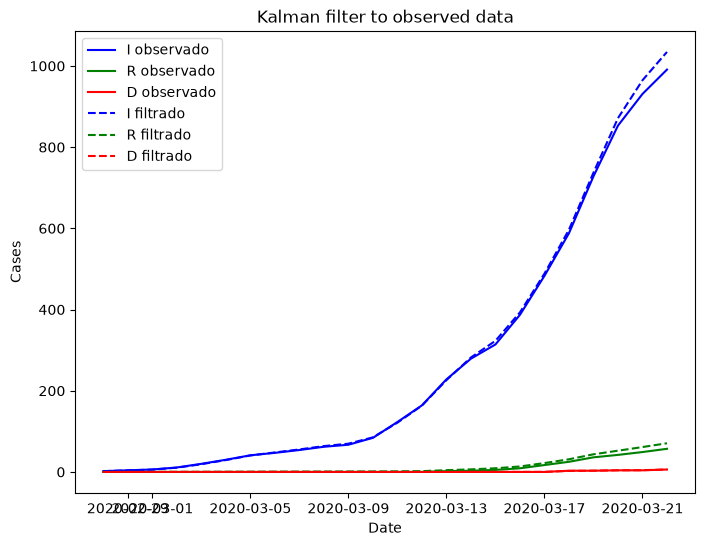

In [3]:
plt.figure(figsize=(8, 6))
plt.plot(df_obs.index, df_obs["I"], label="I observado", color="blue")
plt.plot(df_obs.index, df_obs["R"], label="R observado", color="green")
plt.plot(df_obs.index, df_obs["D"], label="D observado", color="red")
plt.plot(df_filtrado.index, df_filtrado["I_filtrado"], label="I filtrado", color="blue", linestyle="--")
plt.plot(df_filtrado.index, df_filtrado["R_filtrado"], label="R filtrado", color="green", linestyle="--")
plt.plot(df_filtrado.index, df_filtrado["D_filtrado"], label="D filtrado", color="red", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.title("Kalman filter to observed data")
plt.legend()